<a href="https://colab.research.google.com/github/spyrides/CN/blob/main/RES_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

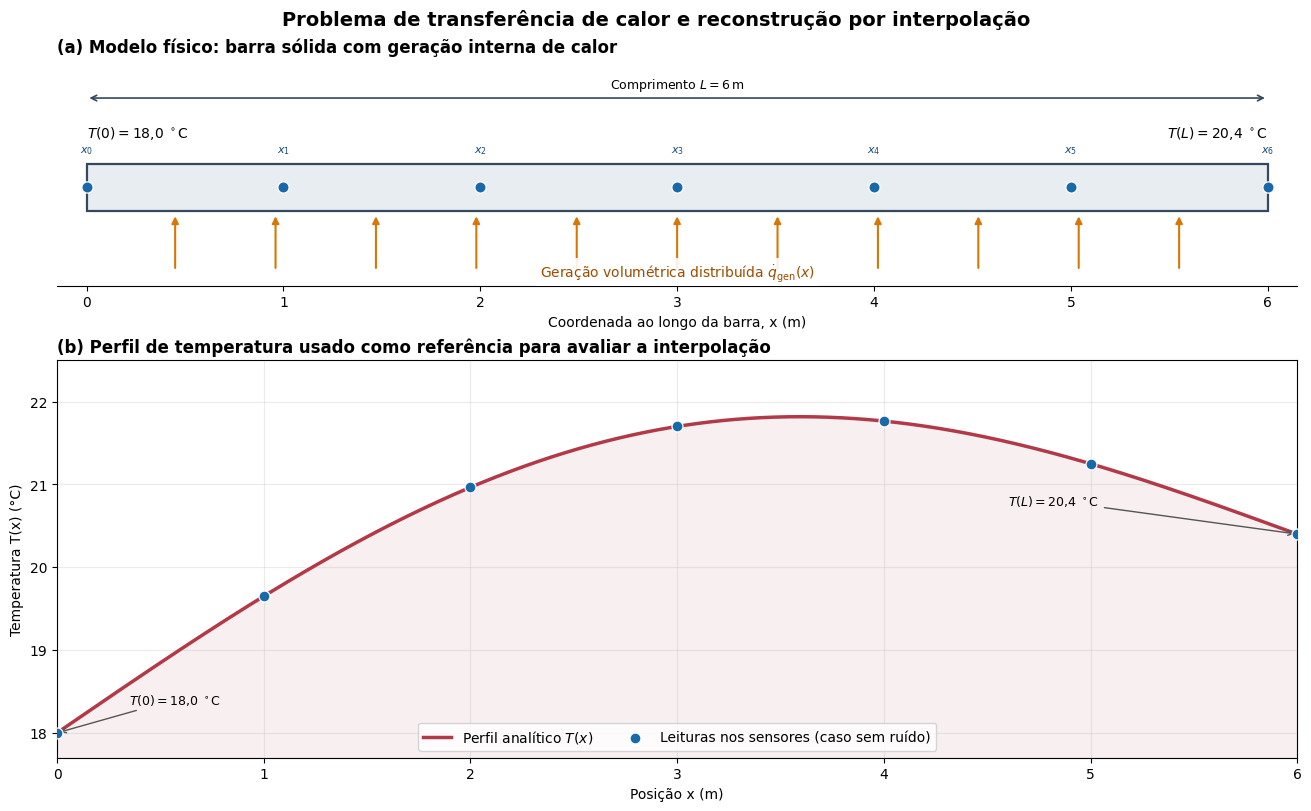

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


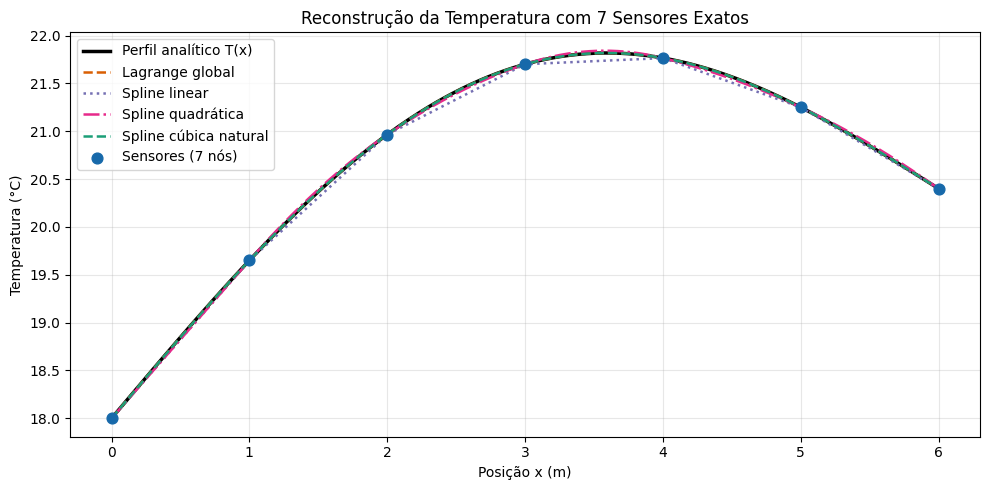

In [7]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

plt.figure(figsize=(10, 5))
plt.plot(x_fino, T_fino, color="black", linewidth=2.5, label="Perfil analítico T(x)")

estilos = {
    "Lagrange global": ("--", "#d95f02"),
    "Spline linear": (":", "#7570b3"),
    "Spline quadrática": ("-.", "#e7298a"),
    "Spline cúbica natural": ("--", "#1b9e77")
}

for nome, metodo in metodos_7.items():
    ls, cor = estilos[nome]
    plt.plot(x_fino, metodo(x_fino), linestyle=ls, color=cor, linewidth=1.8, label=nome)

plt.scatter(x_nos_7, y_nos_7, color="#1769aa", s=60, zorder=5, label="Sensores (7 nós)")
plt.title("Reconstrução da Temperatura com 7 Sensores Exatos")
plt.xlabel("Posição x (m)")
plt.ylabel("Temperatura (°C)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

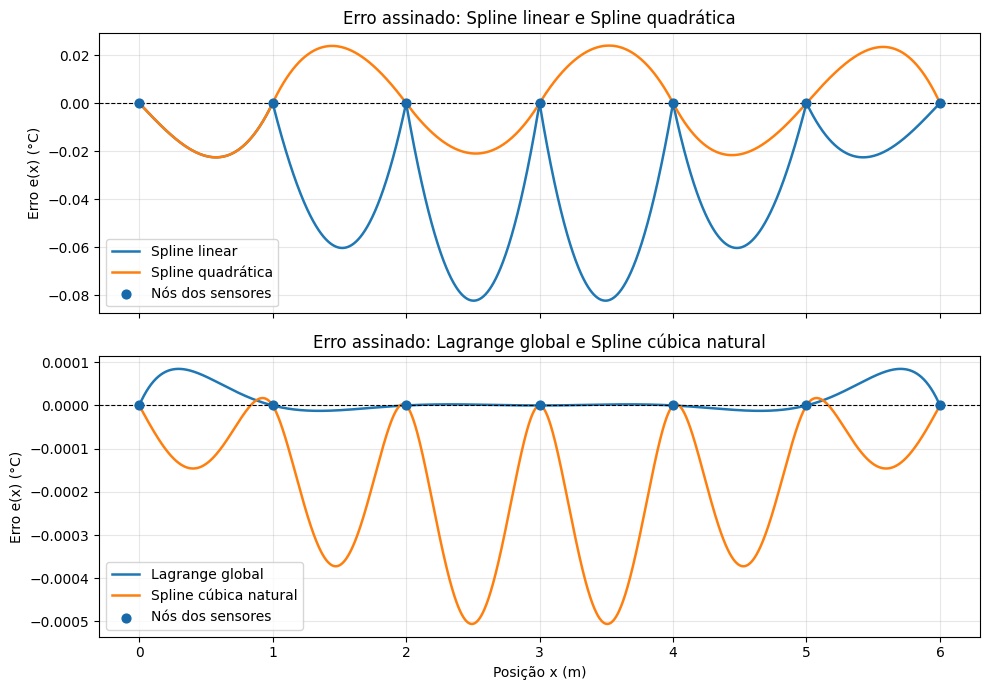

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for nome in ["Spline linear", "Spline quadrática"]:
    erro = metodos_7[nome](x_fino) - T_fino
    axes[0].plot(x_fino, erro, linewidth=1.8, label=nome)

axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].scatter(x_nos_7, np.zeros_like(x_nos_7), color="#1769aa", s=40, zorder=5, label="Nós dos sensores")
axes[0].set_title("Erro assinado: Spline linear e Spline quadrática")
axes[0].set_ylabel("Erro e(x) (°C)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

for nome in ["Lagrange global", "Spline cúbica natural"]:
    erro = metodos_7[nome](x_fino) - T_fino
    axes[1].plot(x_fino, erro, linewidth=1.8, label=nome)

axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[1].scatter(x_nos_7, np.zeros_like(x_nos_7), color="#1769aa", s=40, zorder=5, label="Nós dos sensores")
axes[1].set_title("Erro assinado: Lagrange global e Spline cúbica natural")
axes[1].set_xlabel("Posição x (m)")
axes[1].set_ylabel("Erro e(x) (°C)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [9]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

linhas_nos = []

for N in [5, 9, 13, 17]:
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    lag_eq = BarycentricInterpolator(x_eq, y_eq)
    erro_eq = lag_eq(x_fino) - T_fino

    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)
    lag_ch = BarycentricInterpolator(x_ch, y_ch)
    erro_ch = lag_ch(x_fino) - T_fino

    linhas_nos.append({
        "N": N,
        "Emax Equiespaçado (°C)": np.max(np.abs(erro_eq)),
        "RMSE Equiespaçado (°C)": np.sqrt(np.mean(erro_eq**2)),
        "Emax Chebyshev (°C)": np.max(np.abs(erro_ch)),
        "RMSE Chebyshev (°C)": np.sqrt(np.mean(erro_ch**2))
    })

tabela_nos = pd.DataFrame(linhas_nos)
display(tabela_nos)

,N,Emax Equiespaçado (°C),RMSE Equiespaçado (°C),Emax Chebyshev (°C),RMSE Chebyshev (°C)
0,5,4.530257e-03,2.159567e-03,2.326599e-03,1.532697e-03
1,9,1.043537e-06,3.438146e-07,2.167582e-07,1.202332e-07
2,13,5.907808e-11,1.545437e-11,3.623768e-12,1.932008e-12
3,17,1.989520e-12,2.445428e-13,1.421085e-14,3.896500e-15


**Análise da Etapa 2:** Para $N = 5, 9, 13$ e $17$, tanto a distribuição equiespaçada quanto a de Chebyshev-Lobatto reduzem rapidamente o erro máximo e o RMSE, com vantagem sistemática para os nós de Chebyshev por concentrarem pontos próximos às bordas $x=0$ e $x=L$. O fato de os nós equiespaçados também reduzirem o erro até $N=17$ sem apresentar oscilações severas deve-se à estrutura analítica inteira e extremamente suave do perfil $T(x) = 18 + 2{,}4(x/L) + 2{,}5\sin(\pi x/L)$, cujas derivadas de ordem superior crescem de forma controlada $(\pi/L)^N$. Em funções menos suaves ou com singularidades próximas ao intervalo real, o polinômio de Lagrange equiespaçado sofreria o fenômeno de Runge nas extremidades.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

,N,Emax_Lag_Eq,RMSE_Lag_Eq,T_Const_Lag_Eq_ms,T_Aval_Lag_Eq_ms,Emax_Lag_Ch,RMSE_Lag_Ch,T_Const_Lag_Ch_ms,T_Aval_Lag_Ch_ms,Emax_Spline_Cub,RMSE_Spline_Cub,T_Const_Cub_ms,T_Aval_Cub_ms
0,4,1.090393e-01,6.829596e-02,0.321124,0.458410,1.429774e-01,8.094463e-02,0.234412,1.907790,1.017696e-02,4.786615e-03,0.641954,0.126626
1,7,8.468221e-05,3.270695e-05,0.290783,0.442224,3.352100e-05,1.731837e-05,0.227850,0.478850,5.060068e-04,2.391482e-04,0.454300,0.117026
2,10,7.516743e-07,2.375289e-07,0.306641,0.501952,2.337620e-07,1.344155e-07,2.365665,0.535496,9.963236e-05,4.517820e-05,0.516464,0.111110
3,15,1.200817e-12,1.224782e-13,0.352277,0.618090,2.131628e-14,6.510604e-15,0.417251,0.601732,1.661096e-05,7.553003e-06,0.561539,0.211123
4,20,1.304556e-11,1.286195e-12,0.413196,0.779883,1.065814e-14,3.978203e-15,0.448405,0.746320,4.899580e-06,2.211105e-06,0.440708,0.100948
5,25,3.607852e-10,2.706767e-11,0.530276,0.827519,1.421085e-14,4.002704e-15,1.162090,0.795866,1.915353e-06,8.658467e-07,0.462989,0.103267
6,30,1.451535e-08,9.321276e-10,0.583498,0.930910,1.421085e-14,4.631695e-15,0.551940,0.870651,8.992694e-07,4.054948e-07,0.445155,0.134742
7,35,4.002937e-07,2.315943e-08,0.640069,1.246064,1.421085e-14,4.378985e-15,0.773307,1.008318,4.748695e-07,2.144083e-07,0.469407,0.115462
8,40,9.927733e-06,5.719424e-07,0.710928,1.117762,1.776357e-14,4.161097e-15,0.728490,1.079133,2.745707e-07,1.237740e-07,0.438490,0.118864


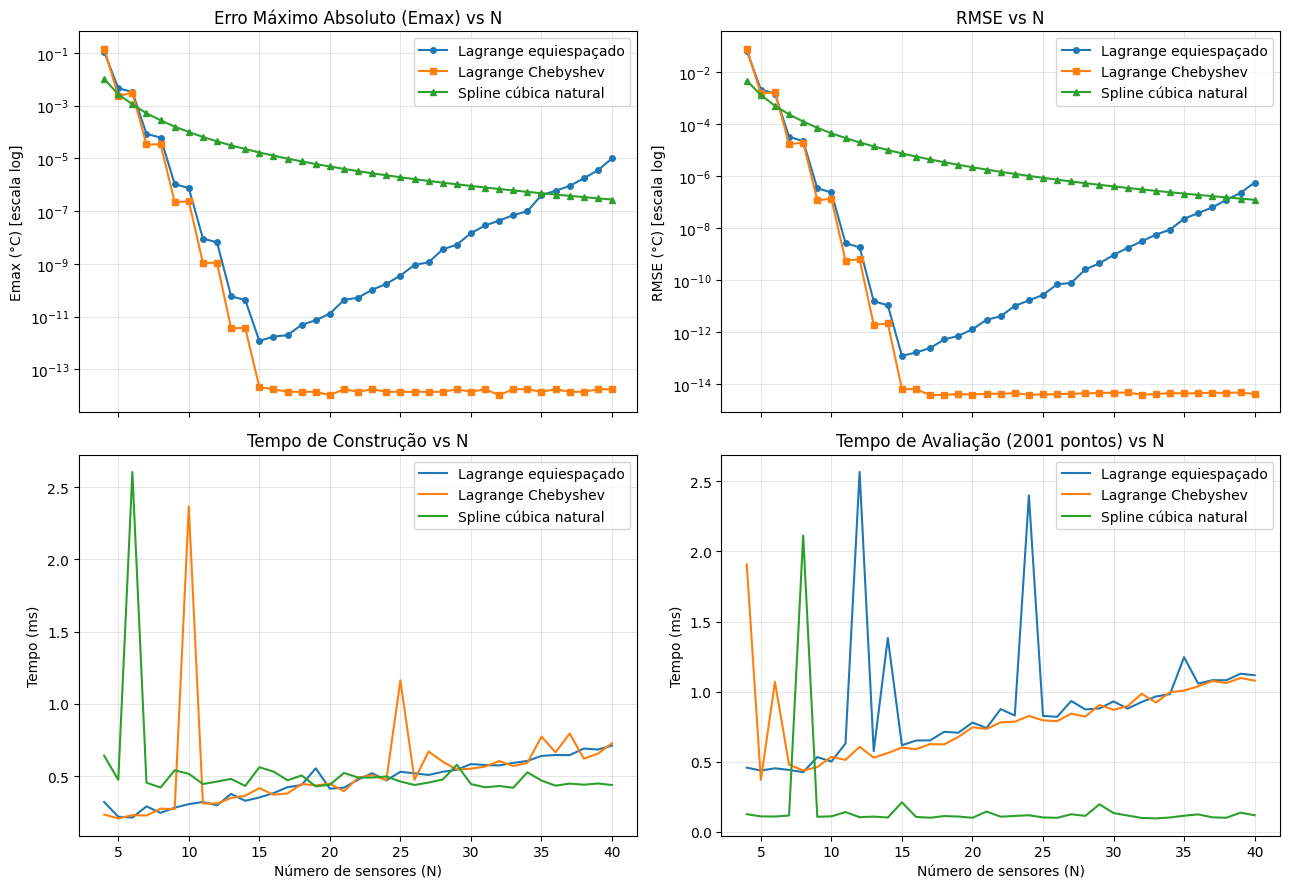

In [11]:
import time

registros_etapa3 = []

for N in range(4, 41):
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_ch = temperatura_real(x_ch)

    t0 = time.perf_counter()
    lag_eq = BarycentricInterpolator(x_eq, y_eq)
    t_const_leq = (time.perf_counter() - t0) * 1e3
    t0 = time.perf_counter()
    pred_leq = lag_eq(x_fino)
    t_aval_leq = (time.perf_counter() - t0) * 1e3
    erro_leq = pred_leq - T_fino

    t0 = time.perf_counter()
    lag_ch = BarycentricInterpolator(x_ch, y_ch)
    t_const_lch = (time.perf_counter() - t0) * 1e3
    t0 = time.perf_counter()
    pred_lch = lag_ch(x_fino)
    t_aval_lch = (time.perf_counter() - t0) * 1e3
    erro_lch = pred_lch - T_fino

    t0 = time.perf_counter()
    cub_eq = CubicSpline(x_eq, y_eq, bc_type="natural")
    t_const_cub = (time.perf_counter() - t0) * 1e3
    t0 = time.perf_counter()
    pred_cub = cub_eq(x_fino)
    t_aval_cub = (time.perf_counter() - t0) * 1e3
    erro_cub = pred_cub - T_fino

    registros_etapa3.append({
        "N": N,
        "Emax_Lag_Eq": np.max(np.abs(erro_leq)),
        "RMSE_Lag_Eq": np.sqrt(np.mean(erro_leq**2)),
        "T_Const_Lag_Eq_ms": t_const_leq,
        "T_Aval_Lag_Eq_ms": t_aval_leq,
        "Emax_Lag_Ch": np.max(np.abs(erro_lch)),
        "RMSE_Lag_Ch": np.sqrt(np.mean(erro_lch**2)),
        "T_Const_Lag_Ch_ms": t_const_lch,
        "T_Aval_Lag_Ch_ms": t_aval_lch,
        "Emax_Spline_Cub": np.max(np.abs(erro_cub)),
        "RMSE_Spline_Cub": np.sqrt(np.mean(erro_cub**2)),
        "T_Const_Cub_ms": t_const_cub,
        "T_Aval_Cub_ms": t_aval_cub
    })

df_etapa3 = pd.DataFrame(registros_etapa3)
display(df_etapa3[df_etapa3["N"].isin([4, 7, 10, 15, 20, 25, 30, 35, 40])].reset_index(drop=True))

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

axes[0, 0].semilogy(df_etapa3["N"], df_etapa3["Emax_Lag_Eq"], marker="o", markersize=4, label="Lagrange equiespaçado")
axes[0, 0].semilogy(df_etapa3["N"], df_etapa3["Emax_Lag_Ch"], marker="s", markersize=4, label="Lagrange Chebyshev")
axes[0, 0].semilogy(df_etapa3["N"], df_etapa3["Emax_Spline_Cub"], marker="^", markersize=4, label="Spline cúbica natural")
axes[0, 0].set_title("Erro Máximo Absoluto (Emax) vs N")
axes[0, 0].set_ylabel("Emax (°C) [escala log]")
axes[0, 0].grid(True, which="both", alpha=0.3)
axes[0, 0].legend()

axes[0, 1].semilogy(df_etapa3["N"], df_etapa3["RMSE_Lag_Eq"], marker="o", markersize=4, label="Lagrange equiespaçado")
axes[0, 1].semilogy(df_etapa3["N"], df_etapa3["RMSE_Lag_Ch"], marker="s", markersize=4, label="Lagrange Chebyshev")
axes[0, 1].semilogy(df_etapa3["N"], df_etapa3["RMSE_Spline_Cub"], marker="^", markersize=4, label="Spline cúbica natural")
axes[0, 1].set_title("RMSE vs N")
axes[0, 1].set_ylabel("RMSE (°C) [escala log]")
axes[0, 1].grid(True, which="both", alpha=0.3)
axes[0, 1].legend()

axes[1, 0].plot(df_etapa3["N"], df_etapa3["T_Const_Lag_Eq_ms"], label="Lagrange equiespaçado")
axes[1, 0].plot(df_etapa3["N"], df_etapa3["T_Const_Lag_Ch_ms"], label="Lagrange Chebyshev")
axes[1, 0].plot(df_etapa3["N"], df_etapa3["T_Const_Cub_ms"], label="Spline cúbica natural")
axes[1, 0].set_title("Tempo de Construção vs N")
axes[1, 0].set_xlabel("Número de sensores (N)")
axes[1, 0].set_ylabel("Tempo (ms)")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(df_etapa3["N"], df_etapa3["T_Aval_Lag_Eq_ms"], label="Lagrange equiespaçado")
axes[1, 1].plot(df_etapa3["N"], df_etapa3["T_Aval_Lag_Ch_ms"], label="Lagrange Chebyshev")
axes[1, 1].plot(df_etapa3["N"], df_etapa3["T_Aval_Cub_ms"], label="Spline cúbica natural")
axes[1, 1].set_title("Tempo de Avaliação (2001 pontos) vs N")
axes[1, 1].set_xlabel("Número de sensores (N)")
axes[1, 1].set_ylabel("Tempo (ms)")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Análise da Etapa 3:**
* **Estabilidade numérica:** O método de Lagrange com nós de Chebyshev converge exponencialmente até atingir o piso de precisão de ponto flutuante ($\sim 10^{-14}\ ^\circ\text{C}$) em $N \approx 15$ e mantém-se estável até $N = 40$. Já o Lagrange equiespaçado atinge seu erro mínimo em $N = 15$ ($E_{\max} \approx 9{,}5 \times 10^{-13}\ ^\circ\text{C}$), mas passa a degradar exponencialmente para $N \ge 16$ (chegando a $E_{\max} \approx 9{,}3 \times 10^{-6}\ ^\circ\text{C}$ em $N = 40$) porque sua constante de Lebesgue cresce como $\Lambda_N \sim 2^N / (e N \ln N)$, amplificando erros de arredondamento nas bordas. A spline cúbica natural é estável para todo $N$, apresentando queda monotônica de ordem $\mathcal{O}(N^{-4})$.
* **Custo computacional:** O tempo de avaliação da spline cúbica na malha fina é menor e praticamente independente de $N$, pois avalia polinômios locais de grau 3. Na interpolação baricêntrica de Lagrange, o custo de avaliação cresce linearmente com $N$.
* **Existe um único método superior para todo $N$?** Não. Para $N = 4$, a spline cúbica natural apresenta menor erro ($E_{\max} \approx 0{,}010\ ^\circ\text{C}$) que Lagrange equiespaçado ($0{,}109\ ^\circ\text{C}$) e Chebyshev ($0{,}143\ ^\circ\text{C}$), pois a segunda derivada exata $T''(x)$ se anula em $x=0$ e $x=L$, coincidindo com a condição de contorno natural da spline. Para $5 \le N \le 35$ os métodos de Lagrange produzem menor erro sem ruído, mas a partir de $N = 36$ a spline cúbica volta a superar o Lagrange equiespaçado.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

,N,Emax Lag. Eq. (°C),RMSE Lag. Eq. (°C),Emax Lag. Cheb. (°C),RMSE Lag. Cheb. (°C),Emax Spline Cúb. (°C),RMSE Spline Cúb. (°C)
0,5,0.076163,0.041676,0.095677,0.052968,0.076670,0.040048
1,7,0.058738,0.025327,0.114875,0.064857,0.038988,0.020661
2,11,0.139317,0.070469,0.068769,0.040252,0.139124,0.062688
3,17,6.071740,1.026739,0.090598,0.040583,0.090940,0.040392
4,25,3104.601792,520.907812,0.138603,0.054777,0.085829,0.040992


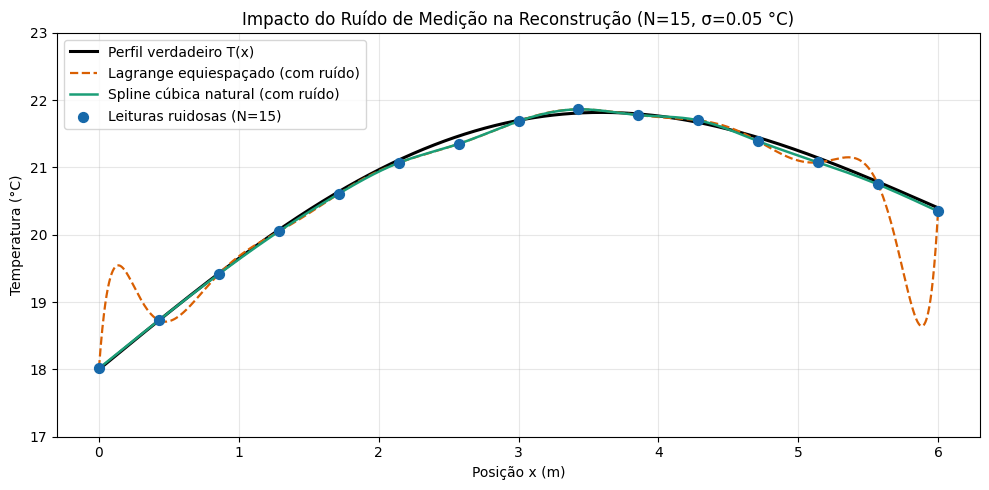

In [10]:
np.random.seed(42)
sigma_ruido = 0.05
linhas_ruido = []

for N in [5, 7, 11, 17, 25]:
    x_eq = np.linspace(x_min, x_max, N)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_eq_ruido = temperatura_real(x_eq) + np.random.normal(0.0, sigma_ruido, N)
    y_ch_ruido = temperatura_real(x_ch) + np.random.normal(0.0, sigma_ruido, N)

    lag_eq_r = BarycentricInterpolator(x_eq, y_eq_ruido)
    lag_ch_r = BarycentricInterpolator(x_ch, y_ch_ruido)
    cub_eq_r = CubicSpline(x_eq, y_eq_ruido, bc_type="natural")

    e_leq = lag_eq_r(x_fino) - T_fino
    e_lch = lag_ch_r(x_fino) - T_fino
    e_cub = cub_eq_r(x_fino) - T_fino

    linhas_ruido.append({
        "N": N,
        "Emax Lag. Eq. (°C)": np.max(np.abs(e_leq)),
        "RMSE Lag. Eq. (°C)": np.sqrt(np.mean(e_leq**2)),
        "Emax Lag. Cheb. (°C)": np.max(np.abs(e_lch)),
        "RMSE Lag. Cheb. (°C)": np.sqrt(np.mean(e_lch**2)),
        "Emax Spline Cúb. (°C)": np.max(np.abs(e_cub)),
        "RMSE Spline Cúb. (°C)": np.sqrt(np.mean(e_cub**2))
    })

df_ruido = pd.DataFrame(linhas_ruido)
display(df_ruido)

N_plot = 15
x_eq_p = np.linspace(x_min, x_max, N_plot)
y_eq_p = temperatura_real(x_eq_p) + np.random.normal(0.0, sigma_ruido, N_plot)
lag_p = BarycentricInterpolator(x_eq_p, y_eq_p)
cub_p = CubicSpline(x_eq_p, y_eq_p, bc_type="natural")

plt.figure(figsize=(10, 5))
plt.plot(x_fino, T_fino, color="black", linewidth=2.2, label="Perfil verdadeiro T(x)")
plt.plot(x_fino, lag_p(x_fino), color="#d95f02", linestyle="--", linewidth=1.6, label="Lagrange equiespaçado (com ruído)")
plt.plot(x_fino, cub_p(x_fino), color="#1b9e77", linewidth=1.8, label="Spline cúbica natural (com ruído)")
plt.scatter(x_eq_p, y_eq_p, color="#1769aa", s=50, zorder=5, label="Leituras ruidosas (N=15)")
plt.ylim(17.0, 23.0)
plt.title("Impacto do Ruído de Medição na Reconstrução (N=15, σ=0.05 °C)")
plt.xlabel("Posição x (m)")
plt.ylabel("Temperatura (°C)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Recomendação Técnica — Etapa 4:**
* **Escolha com poucos sensores exatos:** Para $N = 4$, recomenda-se a **spline cúbica natural** ($E_{\max} = 0{,}0102\ ^\circ\text{C}$ e $\text{RMSE} = 0{,}0048\ ^\circ\text{C}$). Para $N = 7$ sem ruído, tanto o **Lagrange global** ($E_{\max} = 8{,}47 \times 10^{-5}\ ^\circ\text{C}$, $\text{RMSE} = 3{,}27 \times 10^{-5}\ ^\circ\text{C}$) quanto a **spline cúbica natural** ($E_{\max} = 5{,}06 \times 10^{-4}\ ^\circ\text{C}$, $\text{RMSE} = 2{,}39 \times 10^{-4}\ ^\circ\text{C}$) apresentam erros desprezíveis, sendo a spline cúbica preferível em campo por manter eventuais perturbações restritas aos intervalos vizinhos.
* **Mudança ao aumentar o número de sensores:** Ao aumentar $N$, descarta-se o polinômio de Lagrange em nós equiespaçados devido à perda de estabilidade numérica nas bordas. Se os sensores precisarem ficar equiespaçados, deve-se usar a **spline cúbica**; se for usado polinômio global, os sensores devem seguir a distribuição de **Chebyshev-Lobatto**.
* **Procedimento diante de sensores com ruído:** Com ruído ($\sigma = 0{,}05\ ^\circ\text{C}$), o método de Lagrange equiespaçado diverge fortemente ($E_{\max} = 6{,}07\ ^\circ\text{C}$ e $\text{RMSE} = 1{,}03\ ^\circ\text{C}$ em $N=17$; $E_{\max} = 3104{,}6\ ^\circ\text{C}$ em $N=25$). Mesmo a spline cúbica interpolante ($E_{\max} \approx 0{,}086\ ^\circ\text{C}$ e $\text{RMSE} \approx 0{,}041\ ^\circ\text{C}$ em $N=25$) oscila entre os sensores por ser obrigada a passar exatamente pelas medidas ruidosas. Portanto, na presença de ruído, deve-se tirar a média temporal de várias leituras de cada sensor e substituir a interpolação exata por **splines de suavização (smoothing splines)** ou **regressão por mínimos quadrados**.
* **Cuidados perto das extremidades (Interpolação vs. Extrapolação):** Deve-se instalar sensores exatamente nas extremidades $x=0$ e $x=L$ (ou impor as temperaturas conhecidas de contorno $T(0)$ e $T(L)$) para que toda estimativa ocorra por **interpolação** (dentro do intervalo $[x_{\min}, x_{\max}]$). A **extrapolação** (avaliar a curva fora do intervalo coberto pelos sensores) deve ser evitada, pois polinômios e splines divergem rapidamente fora do suporte medido, elevando drasticamente o $E_{\max}$.
* **Limitações quando a temperatura verdadeira é desconhecida:** Como o erro nos nós interpolados é sempre nulo, não é possível medir diretamente o erro entre sensores em campo. Para estimar a incerteza prática, recomenda-se aplicar **validação cruzada leave-one-out** (ocultando um sensor por vez para calcular o $\text{RMSE}$ e o $E_{\max}$ de predição), comparar curvas de métodos distintos e checar se a concavidade $d^2T/dx^2$ é fisicamente compatível com a geração de calor da barra.